# Airline Passenger Satisfaction — Modelling and interpretation

Second notebook of the project. It answers three questions:

1. **Which feature-engineering steps actually help?** (ablation study)
2. **Which model of the course predicts satisfaction best?** (comparison of the models trained by `main.py`)
3. **What drives satisfaction according to the models?** (interpretation and error analysis)

The models are trained by `python main.py`, which saves the results in `reports/results/` and the best
model in `models/`. This notebook reads those files, so it does not repeat the long training.

In [1]:
import ast
import copy
import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree

from src import visualization as viz
from src.data import load_split, split_features_target
from src.evaluate import classification_metrics, permutation_importance_table, plot_permutation_importance
from src.model import build_model
from src.preprocessing import build_baseline_preprocessor, build_preprocessor
from src.train import cross_validation
from src.utils import load_config, project_path

pd.set_option("display.max_colwidth", 80)
config = load_config()
FIGURES = project_path(config["paths"]["figures_dir"])
X_train, y_train = split_features_target(load_split(config, "train"), config)
X_test, y_test = split_features_target(load_split(config, "test"), config)

## 1. Ablation study: what does each feature-engineering step add?

We keep **one simple model** (logistic regression, default settings) and the same 5 cross-validation folds,
and we change only the representation: the full feature engineering, then the full version **minus one step**
at a time. The drop when a step is removed is the contribution of that step.

,accuracy,f1,roc_auc,F1 change vs full
full feature engineering,0.9046,0.8896,0.9658,0.0000
without 'not applicable' handling,0.8767,0.8548,0.9290,-0.0349
without log transform,0.9041,0.8891,0.9656,-0.0006
without is_delayed,0.9045,0.8896,0.9658,-0.0000
without age groups,0.9043,0.8894,0.9654,-0.0002
without travel x class,0.9041,0.8891,0.9657,-0.0005
without the wifi flag only,0.8962,0.8801,0.9603,-0.0095
grouped ratings instead of raw,0.8920,0.8734,0.9553,-0.0162
baseline (no feature engineering),0.8752,0.8531,0.9267,-0.0365


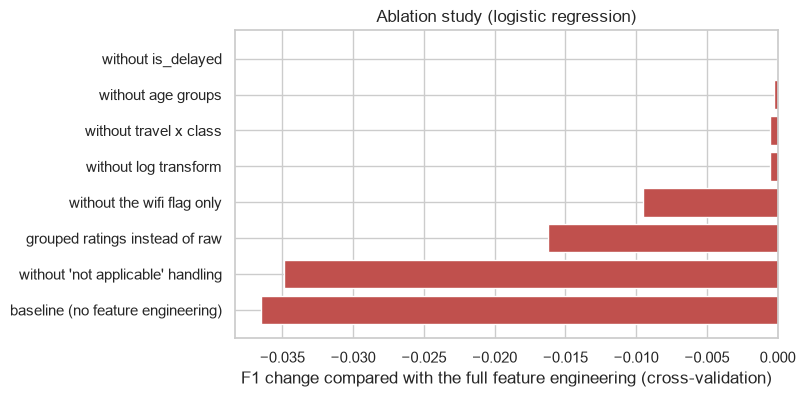

In [2]:
def variant(**changes):
    """Copy of the configuration with some feature-engineering settings changed."""
    changed = copy.deepcopy(config)
    for key, value in changes.items():
        if key in changed["feature_engineering"]["steps"]:
            changed["feature_engineering"]["steps"][key] = value
        else:
            changed["feature_engineering"][key] = value
    return changed

no_wifi_flag = [c for c in config["feature_engineering"]["not_applicable_flags"] if c != "inflight_wifi_service"]
variants = {
    "full feature engineering": build_preprocessor(config),
    "without 'not applicable' handling": build_preprocessor(variant(not_applicable=False)),
    "without log transform": build_preprocessor(variant(log_transform=False)),
    "without is_delayed": build_preprocessor(variant(delay_flag=False)),
    "without age groups": build_preprocessor(variant(age_groups=False)),
    "without travel x class": build_preprocessor(variant(travel_class=False)),
    "without the wifi flag only": build_preprocessor(variant(not_applicable_flags=no_wifi_flag)),
    "grouped ratings instead of raw": build_preprocessor(variant(rating_representation="grouped")),
    "baseline (no feature engineering)": build_baseline_preprocessor(config),
}
rows = {}
for name, preprocessor in variants.items():
    scores = cross_validate(make_pipeline(preprocessor, LogisticRegression(max_iter=2000)), X_train, y_train,
                            cv=cross_validation(config), scoring=["accuracy", "f1", "roc_auc"], n_jobs=-1)
    rows[name] = {m: scores[f"test_{m}"].mean() for m in ["accuracy", "f1", "roc_auc"]}
ablation = pd.DataFrame(rows).T
ablation["F1 change vs full"] = ablation["f1"] - ablation.loc["full feature engineering", "f1"]
display(ablation.round(4))

fig, ax = plt.subplots(figsize=(7, 4))
changes = ablation["F1 change vs full"].drop("full feature engineering").sort_values()
ax.barh(changes.index, changes.values, color=["#c0504d" if v < 0 else "#2a7ab0" for v in changes.values])
ax.set(xlabel="F1 change compared with the full feature engineering (cross-validation)",
       title="Ablation study (logistic regression)")
viz.save_figure(fig, FIGURES, "17_ablation")

**Interpretation**

- **Handling the "not applicable" ratings is the decisive step.** Removing it costs **3.5 F1 points**
  (0.890 → 0.855), almost the whole gain of the feature engineering (the baseline without any engineering
  is at 0.853). The wifi flag alone is worth about 1 point.
- The log transform, `is_delayed`, the age groups and the travel × class category each change the F1-score
  by **less than 0.1 point** for this model. They do not hurt, but they do not measurably help either, probably
  because the other columns already carry most of what they add and the delay effect is small. We keep them because they make the model easier to explain, but a simpler
  pipeline would perform the same; this is an honest result worth reporting.
- **Grouped ratings cost 1.6 points**: summarising 13 ratings by 3 averages loses information. The raw ratings
  are kept for the models; the groups remain useful to describe the results.
- Tree-based models find thresholds and interactions by themselves, so these engineered features matter even
  less for them.

## 2. Model comparison

`main.py` tuned each model of the course with a grid search in 5-fold stratified cross-validation
(search spaces in `configs/config.yaml`), chose the setting with the best cross-validation F1-score,
refit it on the whole training set, then evaluated it on the test set. No choice depends on the test set;
sections 3 and 4 reuse it only to interpret the selected model.

In [3]:
results = pd.read_csv(project_path(config["paths"]["results_dir"]) / "model_results.csv", index_col="model")
display(results[["best_params", "search_seconds"]])
display(results.filter(regex="^(cv|test)_").sort_values("cv_f1", ascending=False).round(4))
card = json.loads(project_path(config["paths"]["model_card"]).read_text(encoding="utf-8"))
print("selected model:", card["model"], card["hyperparameters"])

,best_params,search_seconds
model,,
logistic_regression,{'C': 100},36.1
knn,"{'n_neighbors': 11, 'weights': 'distance'}",57.0
lda,{'shrinkage': 'auto'},3.4
qda,{'reg_param': 0.5},8.0
decision_tree,"{'max_depth': 16, 'min_samples_leaf': 1}",21.8
random_forest,"{'max_depth': 20, 'max_features': 0.5, 'min_samples_leaf': 1}",361.9
gradient_boosting,"{'learning_rate': 0.05, 'max_leaf_nodes': 63}",78.2


,cv_accuracy,cv_precision,cv_recall,cv_f1,cv_roc_auc,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
model,,,,,,,,,,
gradient_boosting,0.9639,0.9744,0.9415,0.9577,0.9951,0.9640,0.9734,0.9439,0.9584,0.9952
random_forest,0.9620,0.9723,0.9391,0.9554,0.9939,0.9630,0.9722,0.9426,0.9572,0.9941
decision_tree,0.9491,0.9482,0.9337,0.9409,0.9688,0.9498,0.9484,0.9367,0.9425,0.9708
knn,0.9331,0.9371,0.9064,0.9215,0.9798,0.9348,0.9399,0.9096,0.9245,0.9808
logistic_regression,0.9046,0.8916,0.8878,0.8897,0.9658,0.9033,0.8890,0.8908,0.8899,0.9664
lda,0.9004,0.8814,0.8898,0.8856,0.9623,0.8989,0.8808,0.8900,0.8854,0.9628
qda,0.8902,0.8917,0.8500,0.8703,0.9559,0.8868,0.8881,0.8491,0.8681,0.9542


selected model: gradient_boosting {'learning_rate': 0.05, 'max_leaf_nodes': 63}


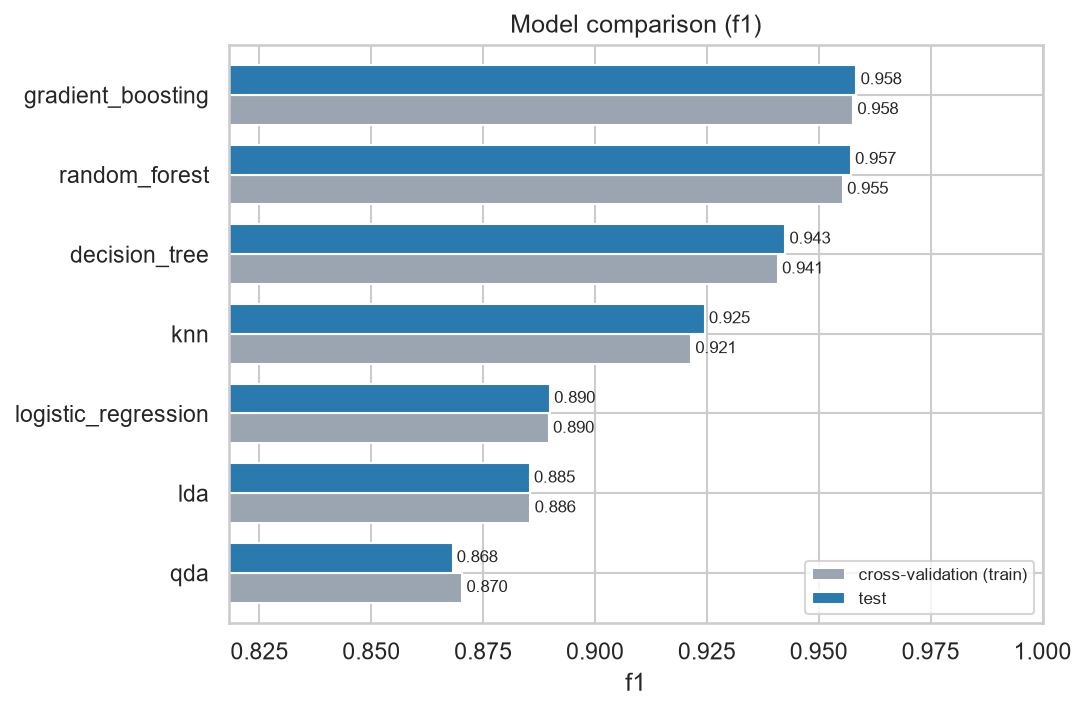

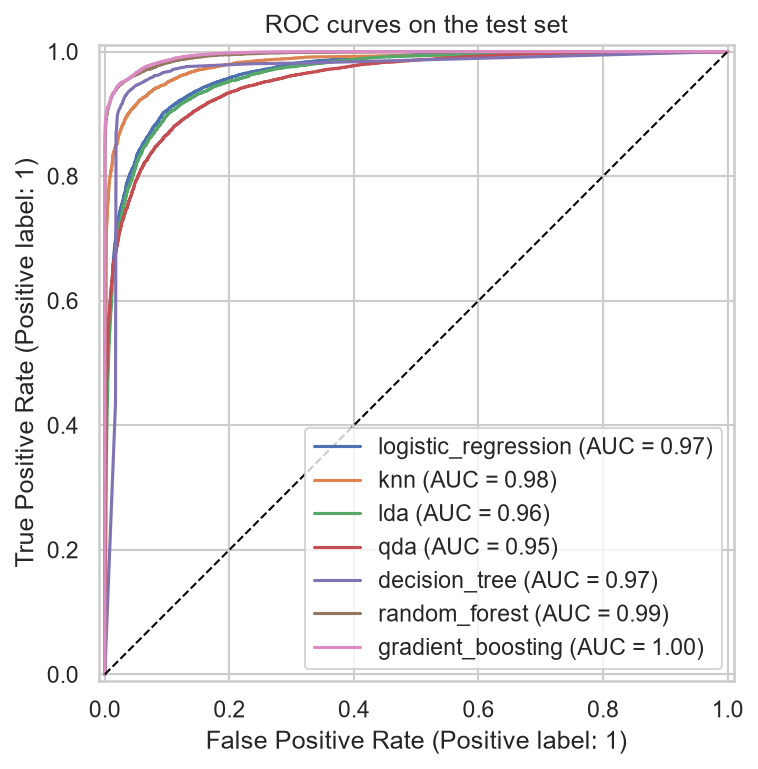

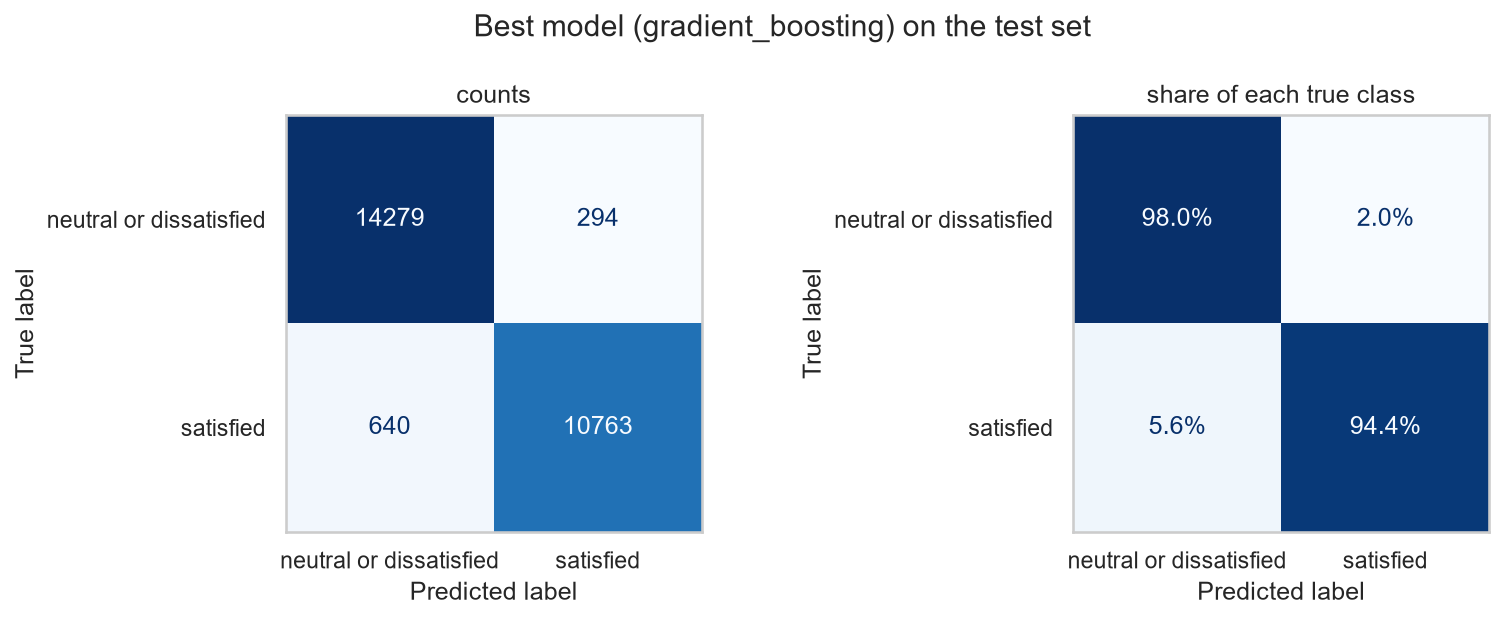

In [4]:
for name in ["13_model_comparison_f1", "14_roc_curves", "15_confusion_matrix"]:
    display(Image(filename=str(FIGURES / f"{name}.png"), width=700))

**Interpretation**

- **Ranking on the test F1-score:** gradient boosting 0.958 ≈ random forest 0.957 > decision tree 0.943 >
  KNN 0.925 > logistic regression 0.890 > LDA 0.885 > QDA 0.868.
- **Cross-validation and test scores agree within 0.003** for every model: the cross-validation estimate is
  reliable and no model overfits the training set.
- **Linear models stop around 0.89.** Satisfaction depends on thresholds (the jump between ratings 3 and 4,
  wifi rated 5) and on interactions (class only matters for business trips). A linear boundary (logistic
  regression, LDA) cannot follow them; trees split on thresholds and combine features naturally, which gives
  about **7 more points**.
- **QDA is last:** it assumes that each class follows a Gaussian distribution, which is a poor description of
  1–5 ratings and 0/1 flags. It needed the strongest regularisation of the grid (0.5).
- **KNN (0.925)** works well once the features are scaled; it uses 11 neighbours weighted by distance.
- **Ensembles beat a single tree by 1.5 points.** A single deep tree (depth 16) has a high variance; averaging
  many trees on bootstrap samples (random forest) or adding small corrective trees one after the other
  (gradient boosting) reduces it — the bias/variance argument of the course.
- **Selected model: gradient boosting** (best cross-validation F1 = 0.958; learning rate 0.05, 63 leaves per
  tree). On the test set it reaches **96.4 % accuracy and a ROC-AUC of 0.995**. It recognises 98.0 % of the
  dissatisfied passengers and 94.4 % of the satisfied ones: when it is wrong, it more often predicts
  "dissatisfied" for a satisfied passenger (640 cases) than the reverse (294 cases).
- It is also much faster to train than the random forest (78 s against 6 min for the whole search).
- Several chosen values sit at the edge of their grid (tree depth 16, forest depth 20, 63 leaves): wider
  grids might gain a little more. For logistic regression, C = 10 and C = 100 give the same score, so the
  regularisation strength does not matter with 100,000 passengers.

## 3. What drives satisfaction?

### 3.1 Permutation importance of the selected model

Each of the 22 original columns is shuffled on the test set, one at a time; the drop of the F1-score
measures how much the model relies on it. Because the whole pipeline is used, the importance of a column
includes its engineered versions (for example `inflight_wifi_service` includes its "not applicable" flag).

,mean drop,std
type_of_travel,0.1897,0.0020
inflight_wifi_service,0.1703,0.0011
customer_type,0.0916,0.0014
online_boarding,0.0380,0.0012
baggage_handling,0.0343,0.0009
inflight_service,0.0297,0.0014
checkin_service,0.0291,0.0005
seat_comfort,0.0265,0.0006
cleanliness,0.0193,0.0007
on_board_service,0.0070,0.0004


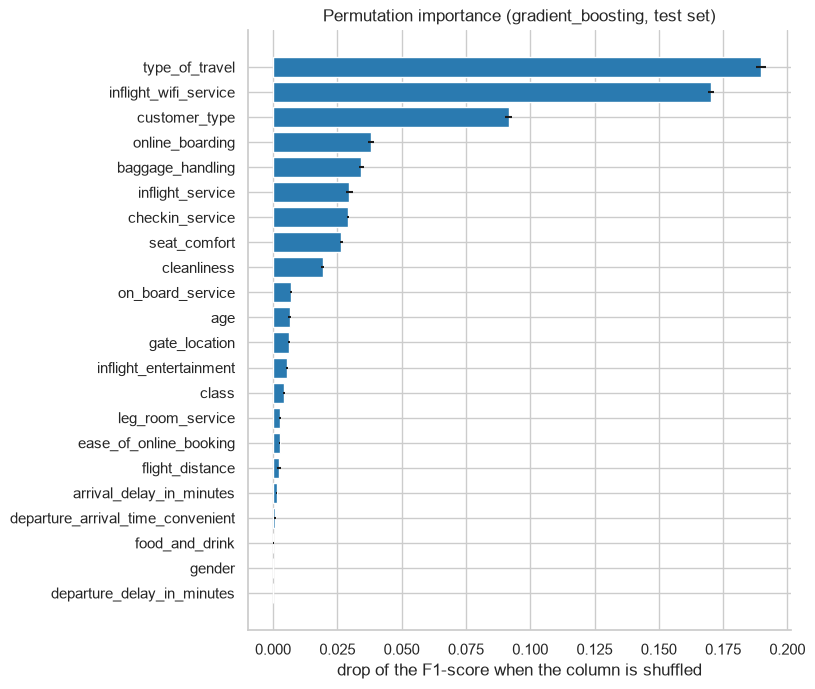

In [5]:
best_model = joblib.load(project_path(config["paths"]["model_file"]))
importance = permutation_importance_table(best_model, X_test, y_test, config)
display(importance.round(4))
plot_permutation_importance(importance, f"Permutation importance ({card['model']}, test set)", FIGURES);

**Interpretation**

- **Type of travel is the most important column** (the F1-score drops by 0.19 when it is shuffled), followed
  by **inflight wifi** (0.17) and **customer type** (0.09).
- Then come **online boarding, baggage handling, inflight service, check-in, seat comfort and cleanliness**
  (drops of 0.02 to 0.04): the digital experience and the on-board services.
- **Class only scores 0.004** although it was a strong factor in the exploration. It does not mean that class is
  irrelevant: the next table shows that its information is redundant with the other columns.
- **Gender, departure/arrival time convenience, food and the delays are close to 0**, which confirms the
  exploratory analysis.
- The high importance of wifi combines two things: the real threshold effect (a rating of 5 means 99 %
  satisfaction) and the "not applicable" pattern seen in notebook 01 (section 4 below checks it).

#### Reliance is not necessity: retraining without a column

Permutation importance tells how much *this* model relies on a column. To see whether the information could be
found elsewhere, we retrain the same model with one column made constant and compare the cross-validation F1-score
(training set only).

In [6]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_score

constants = {"class": "Eco", "type_of_travel": "Business travel", "customer_type": "Loyal Customer",
             "inflight_wifi_service": 3, "online_boarding": 3}
full_f1 = cross_val_score(clone(best_model), X_train, y_train, cv=cross_validation(config), scoring="f1").mean()
retrained = {}
for column, value in constants.items():
    score = cross_val_score(clone(best_model), X_train.assign(**{column: value}), y_train,
                            cv=cross_validation(config), scoring="f1").mean()
    retrained[column] = {"permutation drop (test)": importance.loc[column, "mean drop"],
                         "F1 lost when retrained without it (CV)": full_f1 - score}
print(f"F1 with all columns: {full_f1:.4f}")
display(pd.DataFrame(retrained).T.round(4))

F1 with all columns: 0.9577


,permutation drop (test),F1 lost when retrained without it (CV)
class,0.0042,-0.0000
type_of_travel,0.1897,0.0067
customer_type,0.0916,0.0048
inflight_wifi_service,0.1703,0.0239
online_boarding,0.0380,0.0020


**Interpretation**

- **Class is redundant:** without it the F1-score does not change (0.958). The other columns already contain its
  information, which is why its permutation importance is so low.
- **Type of travel is relied on but partly replaceable:** shuffling it costs 0.19, but a model retrained without it
  only loses about 0.007.
- **Wifi is the hardest column to replace** (about 0.024 lost). This includes its "not applicable" pattern.

### 3.2 Logistic-regression coefficients

The logistic regression is less accurate than the best model but directly readable. All numeric features
are standardised, so the coefficients are comparable: a positive coefficient increases the odds of being
satisfied, a negative one decreases them.

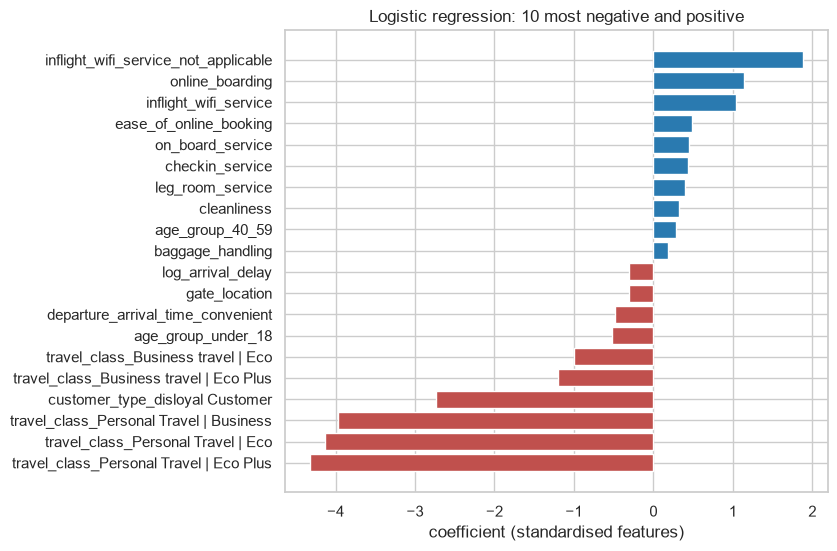

In [7]:
lr_params = ast.literal_eval(results.loc["logistic_regression", "best_params"])
logistic = build_model("logistic_regression", config).set_params(**{f"model__{k}": v for k, v in lr_params.items()})
logistic.fit(X_train, y_train)
names = logistic.named_steps["preprocess"].named_steps["encode"].get_feature_names_out()
coefficients = pd.Series(logistic.named_steps["model"].coef_[0],
                         index=[n.split("__", 1)[1] for n in names]).sort_values()
top = pd.concat([coefficients.head(10), coefficients.tail(10)])
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(top.index, top.values, color=["#c0504d" if v < 0 else "#2a7ab0" for v in top.values])
ax.set(xlabel="coefficient (standardised features)", title="Logistic regression: 10 most negative and positive")
viz.save_figure(fig, FIGURES, "18_logistic_coefficients")

**Interpretation**

- The reference category is a **business trip in Business class**. All personal trips have coefficients
  around **−4**, whatever the class: once the trip is personal, the class no longer helps, exactly as in the
  exploration. Business trips in Eco (−1.0) and Eco Plus (−1.2) are in between.
- **Disloyal customers** have a strong negative coefficient (−2.7).
- Among the services, **online boarding (+1.1) and wifi (+1.0)** come first, then ease of online booking,
  on-board service, check-in, leg room and cleanliness.
- The wifi "not applicable" flag has the largest positive coefficient (+1.9): the model uses the suspicious
  pattern of the data.
- **Gate location and departure/arrival time convenience are negative.** We do not read it as "a better gate makes
  passengers unhappy": these two ratings are correlated with ease of online booking (about 0.5) and wifi (about
  0.35), so their coefficients probably correct those other coefficients. Correlated features make individual
  coefficients hard to read, as seen in notebook 01.
- One-hot categories (0 or 1) and standardised numeric features are not on exactly the same scale, so the sizes
  of the two kinds of coefficients are compared with care.

### 3.3 A small decision tree to read the rules

The course suggests starting with one small tree because its rules are easy to inspect.
A depth-3 tree is far from the best model, but it shows the main splits in plain language.
Trees do not need scaling, so this one is trained on unscaled features: its thresholds are real ratings.

depth-3 tree, test accuracy: 0.862


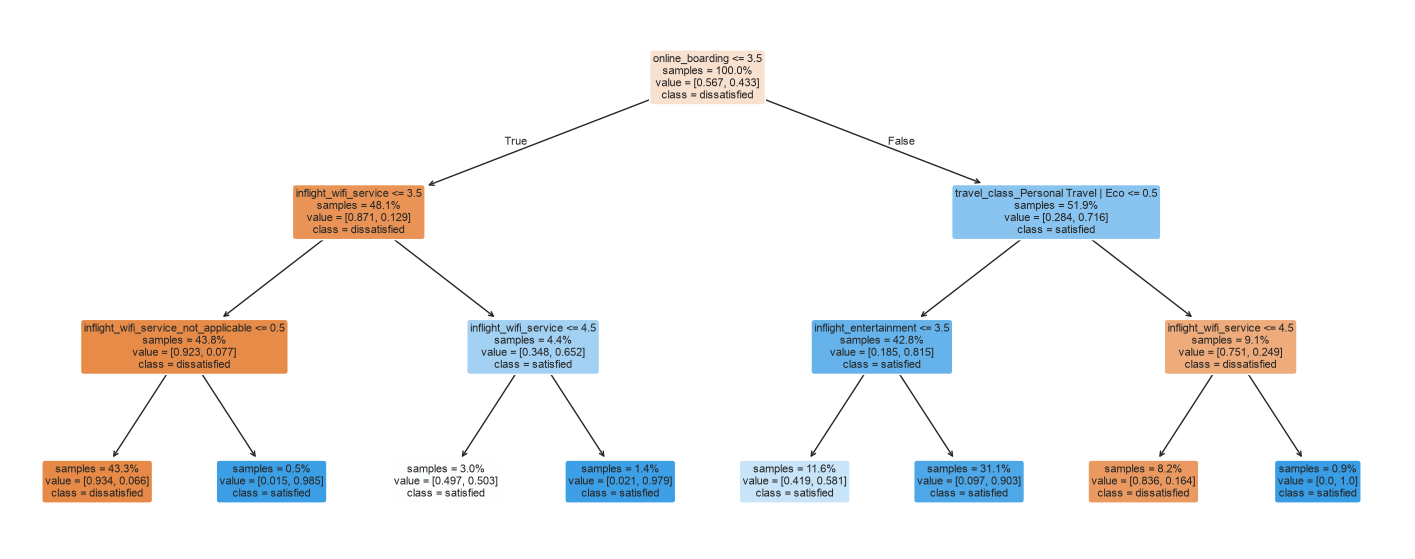

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from src.preprocessing import build_feature_engineer, engineered_columns

categorical, numeric = engineered_columns(config)
unscaled = ColumnTransformer([("categorical", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical),
                              ("numeric", "passthrough", numeric)], verbose_feature_names_out=False)
small_tree = make_pipeline(build_feature_engineer(config), unscaled,
                           DecisionTreeClassifier(max_depth=3, random_state=config["seed"]))
small_tree.fit(X_train, y_train)
tree_names = list(small_tree[1].get_feature_names_out())
print(f"depth-3 tree, test accuracy: {classification_metrics(small_tree, X_test, y_test)['accuracy']:.3f}")
fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(small_tree[-1], feature_names=tree_names, class_names=["dissatisfied", "satisfied"],
          filled=True, rounded=True, impurity=False, proportion=True, fontsize=8, ax=ax)
viz.save_figure(fig, FIGURES, "19_small_tree")

**Interpretation**

The tree reaches 86 % accuracy with only three questions, and its rules can be read directly:

1. **Online boarding and wifi both rated 1 to 3** → 93 % of these passengers are dissatisfied. With online boarding
   1 to 3, a wifi rated 4 gives about 50 %, and a wifi rated 5 or not applicable gives 98 % satisfied.
2. **Online boarding rated 4 or 5** (a 0 is replaced by the median, 4) → most passengers are satisfied, with one exception:
   **personal trips in Eco** stay 84 % dissatisfied, unless their wifi is rated 5.
3. For the others, **inflight entertainment rated 4 or 5** brings satisfaction to 90 %.

These three rules summarise the story of the whole project: online boarding, wifi, the type of trip and the
on-board comfort.

## 4. Where does the selected model make mistakes?

In [9]:
predicted = best_model.predict(X_test)
correct = pd.Series(predicted == y_test.values, index=X_test.index)
by_segment = pd.DataFrame({
    "passengers": X_test.groupby(["type_of_travel", "class"]).size(),
    "satisfaction rate": y_test.groupby([X_test["type_of_travel"], X_test["class"]]).mean(),
    "accuracy": correct.groupby([X_test["type_of_travel"], X_test["class"]]).mean(),
})
display(by_segment.round(3))
wifi_na = X_test["inflight_wifi_service"] == 0
print(f"accuracy when wifi is not applicable: {correct[wifi_na].mean():.3f} ({wifi_na.sum()} passengers)")
print(f"accuracy otherwise: {correct[~wifi_na].mean():.3f}")

passengers  satisfaction rate  accuracy
type_of_travel  class                                            
Business travel Business       11979              0.721     0.979
                Eco             5047              0.313     0.942
                Eco Plus        1012              0.390     0.953
Personal Travel Business         516              0.095     0.957
                Eco             6517              0.102     0.955
                Eco Plus         905              0.088     0.968

accuracy when wifi is not applicable: 1.000 (813 passengers)
accuracy otherwise: 0.963


**Interpretation**

- The model is most accurate for **business trips in Business class (97.9 %)**, where most passengers are
  satisfied, and least accurate for **business trips in Eco (94.2 %)**, the most mixed segment
  (31 % satisfied). Errors concentrate where the outcome is the most uncertain.
- On the **813 test passengers whose wifi is "not applicable", the model is right 100 % of the time**, against
  96.3 % for the others. It fully exploits this pattern. These passengers are only 3 % of the test set, so the
  overall score does not depend on them, but on real data where this pattern does not exist the model could be
  less accurate. This is the main limitation to mention in the report.

## 5. Conclusions

**What drives satisfaction**

1. **The type of trip and loyalty come first.** Business travellers and loyal customers are much more often
   satisfied; personal travellers in economy are the least satisfied group.
2. **The digital experience matters most among the services:** online boarding and inflight wifi.
3. **On-board services follow:** baggage handling, inflight service, check-in, seat comfort, cleanliness and
   entertainment.
4. **Delays, gender, gate location and schedule convenience barely matter.**

**What we learned about the pipeline**

- The decisive preprocessing step is to treat a rating of 0 as **"not applicable"** rather than as a very bad
  rating (+3.5 F1 points for logistic regression). Kaggle documents this meaning for wifi only; for the other
  services it is our assumption. The other engineered features are easier to explain but do
  not change the score.
- Non-linear models win clearly: **gradient boosting reaches a test F1 of 0.958 (accuracy 96.4 %, ROC-AUC
  0.995)**, against 0.890 for logistic regression, which remains the most readable model.

**Limitations and future work**

- The "wifi not applicable" pattern (99.7 % satisfied, 100 % predicted correctly) looks like an artifact of the
  survey; a model trained without it should be compared on new data.
- "Neutral" and "dissatisfied" are merged in one class; a three-class version would be more informative.
- Some best hyperparameters are at the edge of their grids; wider searches could add a little.
- The data comes from one survey of one airline: the conclusions may not transfer to other airlines.

**Recommendations for the airline:** improve online boarding and wifi first, then the on-board staff
services, and target personal travellers in economy, who are rarely satisfied.